# B 部分：车辆运行特征分析

> 数据来源：`data/processed/clean_wide.csv`（A 部分交付的主表，35,306 行 × 69 列）
> 对应报告章节：**数据分析（运行特征部分）**
> 分析对象：3 台设备的 10 秒对齐窗口

本 Notebook 完成四项工作：

1. **车速、转速、加速度随时间的时序分析**；
2. **三台车辆的运行特征对比**——工况、怠速/行驶比例、加减速习惯；
3. **变量相关性分析**（热力图）；
4. **车辆轨迹/位置可视化**。

所有图表由本文件生成并保存到 `figures/`，报告中引用的每一个数值都在本文件内计算得到，可复现。

## 0. 分析口径：三个必须先确认的前置判断

如果直接对主表求均值、画折线，会得到三条错误结论。下面三点决定了后面所有分析的做法。

**（1）观测是稀疏的，不能当作连续时间序列处理。**
主表按 10 秒窗口对齐，每个测量字段只保留窗口内**最后一个非空观测**，没有观测就留空——不补零、不插值、不跨窗口沿用。
53 个测量字段里覆盖率最高的是位置（99.8%），而 `Vehicle speed` 只有 6.4%、`ENGINE RPM` 只有 7.2%。
所以：时序图一律在缺口处断线，不插值；所有统计量只基于「有观测的窗口」，并在图上标注有效样本数。

**（2）三台设备的数据量极不均衡。**
车辆1：1,547 个窗口；车辆2：767 个；车辆3：32,992 个，占全表 93%。
车辆2 的 `Vehicle speed` 只有 88 个有效观测，中位数 5 km/h 却出现 175 km/h 的孤立尖峰。
因此「三车对比」只能作方向性参考，车辆2 的结论尤其需要谨慎。

**（3）POSITION 的坐标口径要先判定，且含无效占位值。**
A 部分已声明 `position_1/2/3` 的字段顺序未确认。本报告不靠猜测，而是用**由相邻定位点反推的速度**与 OBD 车速比对，
在两组竞争假设之间做判别（第 5 节）：结论是 `position_1`=纬度、`position_2`=经度、`position_3`=海拔（米），
三台设备实际位于 13.3°N / 74.7°E 与 13.05°N / 80.24°E 一带。
此外 `(0, 0, 0)` 是「无定位」占位值，占全部定位记录的 **18.5%**，必须在画轨迹前剔除，否则会出现横跨半个地球的假跳变。

In [1]:
from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib
# 用 inline 后端，保证图表既能存盘、又能直接显示在 Notebook 里
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

# 定位项目根目录：无论从仓库根目录还是 notebooks/ 启动都能找到数据
HERE = Path.cwd().resolve()
ROOT = HERE
while not (ROOT / "data" / "processed" / "clean_wide.csv").exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("未找到 data/processed/clean_wide.csv，请在仓库根目录或 notebooks/ 下运行。")
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT))
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)

FONT = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams.update({
    "font.sans-serif": FONT,
    "axes.unicode_minus": False,
    "figure.dpi": 110,
    "savefig.dpi": 170,
    "savefig.bbox": "tight",
    "axes.titlesize": 12,
    "axes.labelsize": 10,
})
sns.set_theme(style="whitegrid", rc={"font.sans-serif": FONT, "axes.unicode_minus": False})

PALETTE = ["#2E5C8A", "#D9822B", "#3C8C6A"]


def save(fig, name, note=None):
    '''统一保存图表并打印提示。'''
    path = FIG / name
    fig.savefig(path)
    print(f"已保存 {path.relative_to(ROOT)}" + (f"  （{note}）" if note else ""))


print("项目根目录 :", ROOT)
print("pandas     :", pd.__version__)
print("matplotlib :", matplotlib.__version__)

项目根目录 : C:\Users\Metanoia\Documents\deepseek-harness\default-workspace\work\repo\vehicle-iot-analysis-main
pandas     : 3.0.1
matplotlib : 3.11.2


## 1. 载入数据与字段划分

按 A 部分 README 的建议，用 `prepare_data.sensor_columns()` 取出 **53 个测量字段**，
避免把告警列（`code_*_count`、`single_alarmClass` 等）和元数据误当成运行特征。

In [2]:
from prepare_data import sensor_columns

clean = pd.read_csv(ROOT / "data/processed/clean_wide.csv", parse_dates=["timestamp", "window_end"])

MEASUREMENTS = sensor_columns(clean)           # 53 个测量字段
device_ids = sorted(clean.deviceId.unique())
DEV_LABEL = {d: f"车辆{i + 1}" for i, d in enumerate(device_ids)}
COLORS = dict(zip(device_ids, PALETTE))
RAW_SHAPE = clean.shape
clean["vehicle"] = clean.deviceId.map(DEV_LABEL)   # 仅用于绘图分组的标签列

print(f"主表规模        : {RAW_SHAPE[0]:,} 行 × {RAW_SHAPE[1]} 列（不含本 Notebook 新增的 vehicle 标签列）")
print(f"测量字段        : {len(MEASUREMENTS)} 个")
print(f"时间范围        : {clean.timestamp.min()} → {clean.timestamp.max()}")
print()
summary = (clean.groupby("vehicle")
           .agg(设备ID=("deviceId", "first"),
                窗口数=("timestamp", "size"),
                起始=("timestamp", "min"),
                结束=("timestamp", "max")))
summary["占比"] = (summary["窗口数"] / len(clean) * 100).round(1).astype(str) + "%"
summary

主表规模        : 35,306 行 × 69 列（不含本 Notebook 新增的 vehicle 标签列）
测量字段        : 53 个
时间范围        : 2020-08-17 00:00:00 → 2020-08-24 12:23:10



,设备ID,窗口数,起始,结束,占比
vehicle,,,,,
车辆1,zRYzhAEAHAABAAAKCRtcAAsAGAB0gBAQ,1547,2020-08-21 14:27:00,2020-08-24 12:23:10,4.4%
车辆2,zRYzhAEAHAABAAAKCRtcAAsANAB0gBAQ,767,2020-08-17 11:31:00,2020-08-19 15:47:00,2.2%
车辆3,zRYzhAEAHAABAAAKCRtcAAsAtwB1gBAQ,32992,2020-08-17 00:00:00,2020-08-23 21:39:50,93.4%


## 2. 观测可用性审计

先看清「哪些字段真的能用」，再决定分析什么。这张图是后面所有取舍依据。

已保存 figures\B01_observation_coverage.png


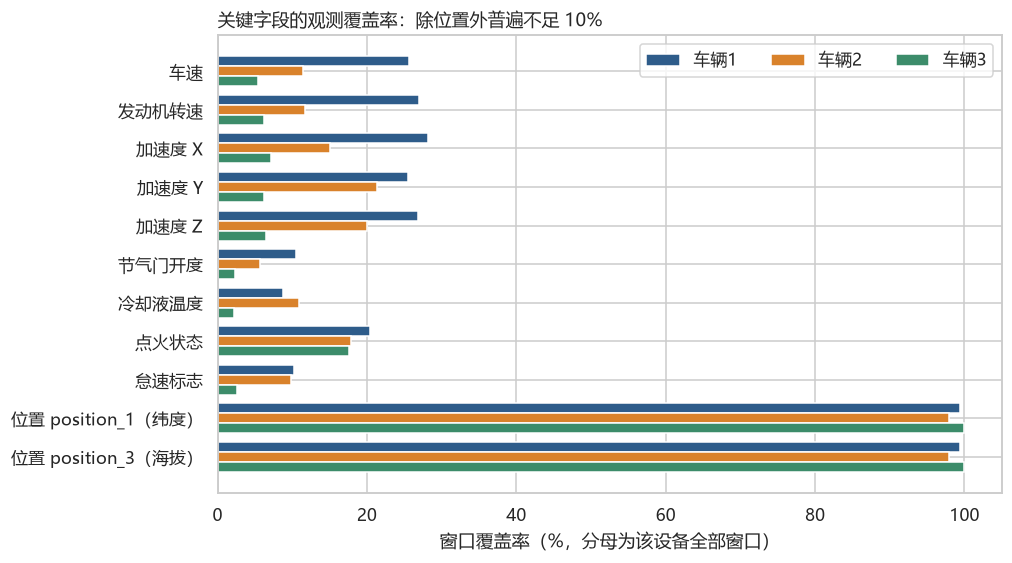

相邻车速观测的间隔分布（秒）:
timestamp
10.0    1701
20.0      98
30.0      96
40.0      34
50.0      23
60.0     156

合计车速有效观测 2,251 个窗口，其中 10 秒紧邻对 1,701 个——这是做加减速分析的可用样本上限。


In [3]:
KEY_SIGNALS = [
    "Vehicle speed", "ENGINE RPM",
    "ACCELERATION X", "ACCELERATION Y", "ACCELERATION Z",
    "THROTTLE POSITION", "ENGINE COOLANT TEMPERATURE",
    "IGNITION_STATUS", "IDLING",
    "position_1", "position_3",
]
SIGNALS_CN = {
    "Vehicle speed": "车速",
    "ENGINE RPM": "发动机转速",
    "ACCELERATION X": "加速度 X",
    "ACCELERATION Y": "加速度 Y",
    "ACCELERATION Z": "加速度 Z",
    "THROTTLE POSITION": "节气门开度",
    "ENGINE COOLANT TEMPERATURE": "冷却液温度",
    "IGNITION_STATUS": "点火状态",
    "IDLING": "怠速标志",
    "position_1": "位置 position_1（纬度）",
    "position_3": "位置 position_3（海拔）",
}

cov = clean.groupby("vehicle")[KEY_SIGNALS].agg(lambda s: s.notna().mean() * 100).T

fig, ax = plt.subplots(figsize=(9.2, 5.4))
y = np.arange(len(KEY_SIGNALS))
h = 0.26
for i, dev in enumerate(device_ids):
    label = DEV_LABEL[dev]
    ax.barh(y + (i - 1) * h, cov[label].reindex(KEY_SIGNALS).values, height=h,
            color=COLORS[dev], label=label)
ax.set_yticks(y)
ax.set_yticklabels([SIGNALS_CN[s] for s in KEY_SIGNALS])
ax.invert_yaxis()
ax.set_xlabel("窗口覆盖率（%，分母为该设备全部窗口）")
ax.set_title("关键字段的观测覆盖率：除位置外普遍不足 10%", loc="left")
ax.legend(title="", ncol=3, loc="upper right")
ax.set_xlim(0, 105)
save(fig, "B01_observation_coverage.png")
plt.show()

# 采样间隔：说明「稀疏」不是数据错乱，而是上报节奏
sp = clean.dropna(subset=["Vehicle speed"]).sort_values(["deviceId", "timestamp"])
dt = sp.groupby("deviceId").timestamp.diff().dt.total_seconds().dropna()
dt = dt[(dt > 0) & (dt <= 60)]
print("相邻车速观测的间隔分布（秒）:")
print(dt.value_counts().sort_index().to_string())
print(f"\n合计车速有效观测 {clean['Vehicle speed'].notna().sum():,} 个窗口，"
      f"其中 10 秒紧邻对 {int((dt == 10).sum()):,} 个——这是做加减速分析的可用样本上限。")

## 3. 车速、转速、加速度的时序分析

三张图共用「缺口断线」的画法：把每个设备的观测重新铺到 10 秒网格上，没有观测的位置留 `NaN`，
matplotlib 会自动断线。**这样折线长度反映的是真实观测，而不是插值出来的假连续。**

已保存 figures\B02_speed_timeseries.png


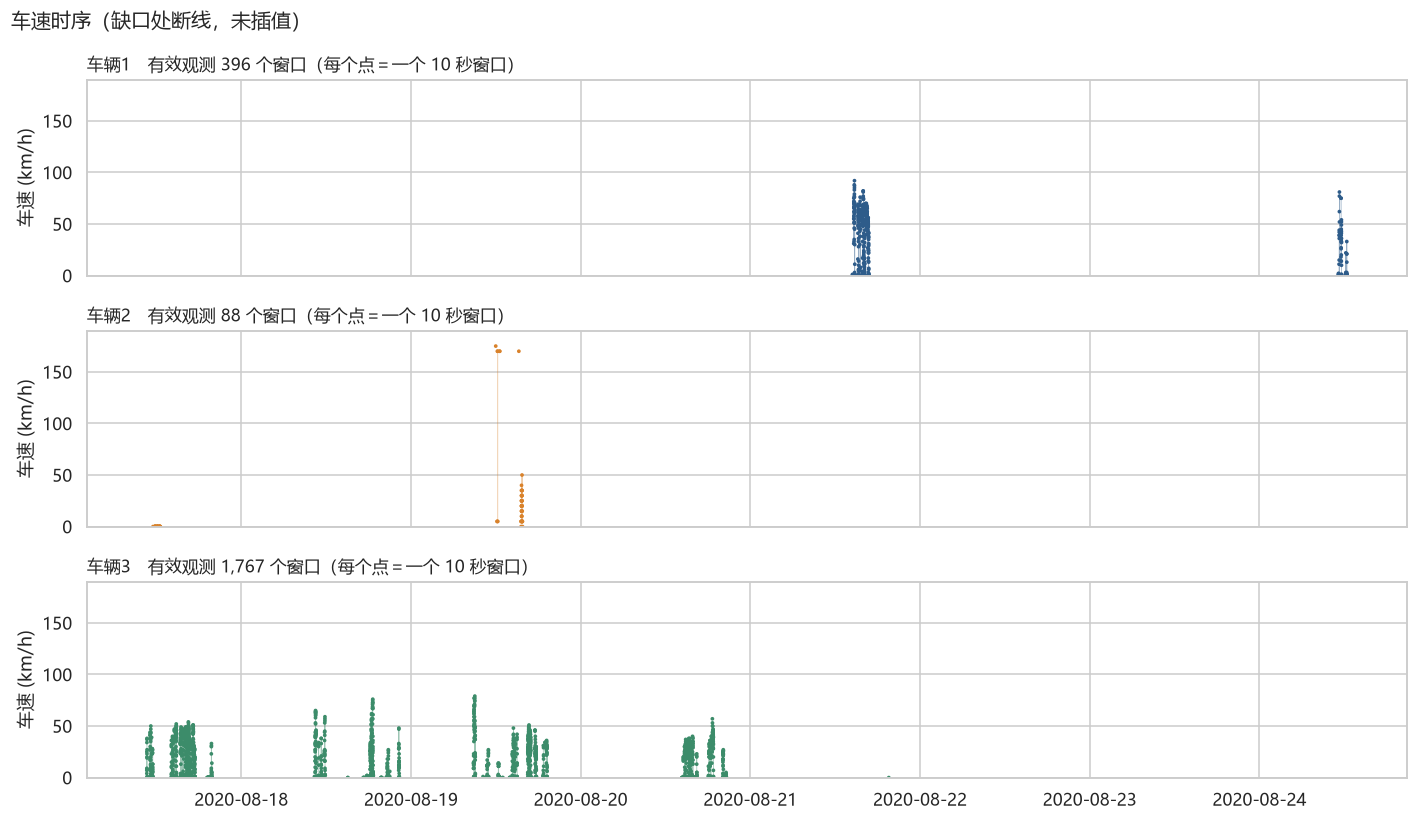

In [4]:
STEP = "10s"


def gap_series(device, column, frame=None):
    '''把某设备的某个字段铺到 10 秒网格上，缺口留 NaN（便于断线绘制）。'''
    src = clean if frame is None else frame
    s = (src.loc[src.deviceId.eq(device)]
         .dropna(subset=[column])
         .set_index("timestamp")[column].sort_index())
    if s.empty:
        return s
    s = s[~s.index.duplicated(keep="last")]
    grid = pd.date_range(s.index.min(), s.index.max(), freq=STEP)
    return s.reindex(grid)


def three_panel(column, ylabel, fname, title, ylim=None, ref=None):
    fig, axes = plt.subplots(3, 1, figsize=(13, 7.6), sharex=True)
    for ax, dev in zip(axes, device_ids):
        s = gap_series(dev, column)
        vals = s.to_numpy(dtype=float)
        ax.plot(s.index, vals, lw=0.5, alpha=0.5, color=COLORS[dev])
        ax.scatter(s.index, vals, s=6, color=COLORS[dev], edgecolors="none")
        ax.set_title(f"{DEV_LABEL[dev]}　有效观测 {int(s.notna().sum()):,} 个窗口（每个点＝一个 10 秒窗口）",
                     loc="left", fontsize=11)
        ax.set_ylabel(ylabel)
        if ref is not None:
            for r in ref:
                ax.axhline(r, color="grey", ls="--", lw=0.7)
        if ylim is not None:
            ax.set_ylim(*ylim)
    fig.suptitle(title, x=0.01, ha="left", fontsize=13)
    fig.tight_layout()
    save(fig, fname)
    plt.show()


three_panel("Vehicle speed", "车速 (km/h)", "B02_speed_timeseries.png",
            "车速时序（缺口处断线，未插值）", ylim=(0, 190))

已保存 figures\B03_rpm_timeseries.png


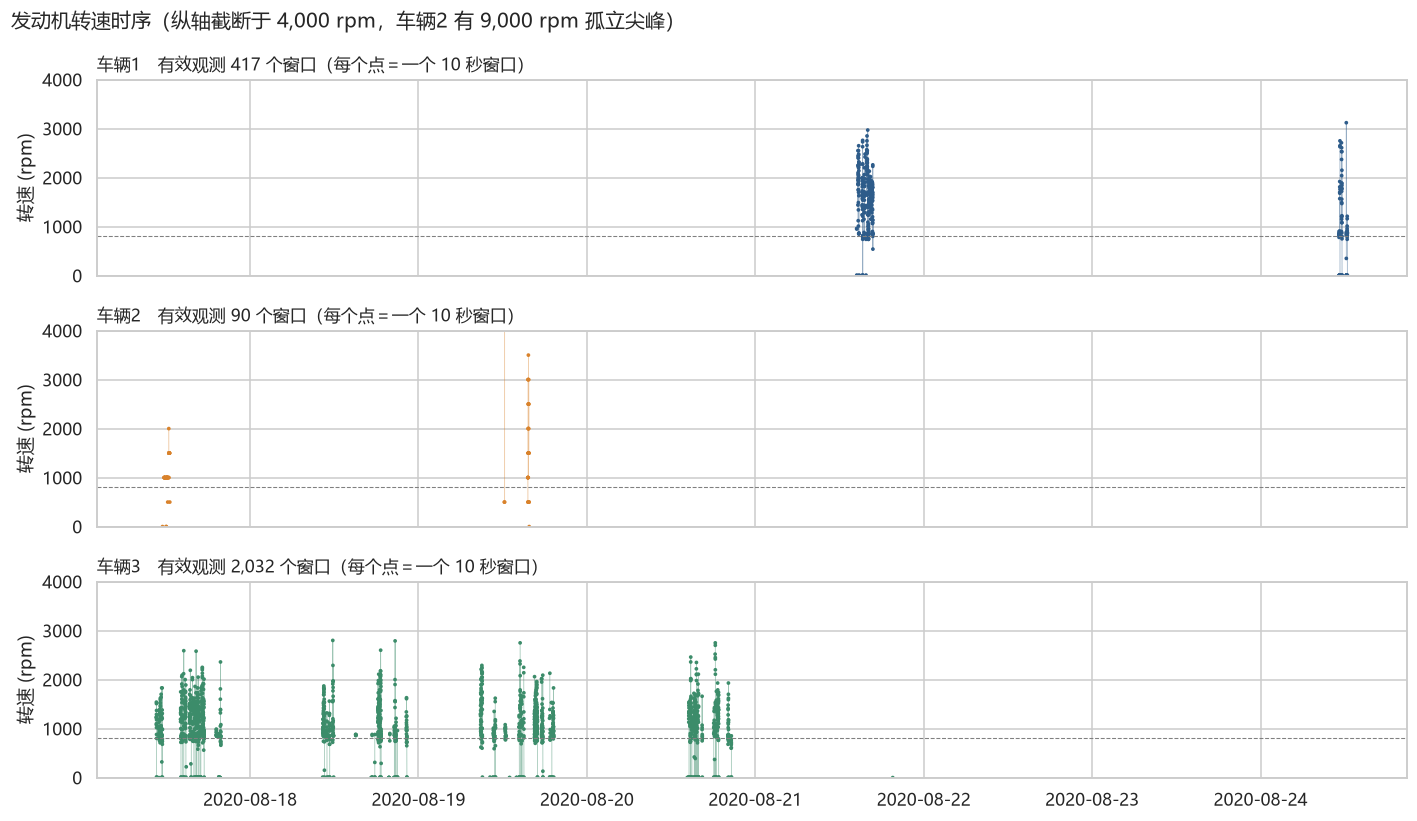

In [5]:
three_panel("ENGINE RPM", "转速 (rpm)", "B03_rpm_timeseries.png",
            "发动机转速时序（纵轴截断于 4,000 rpm，车辆2 有 9,000 rpm 孤立尖峰）",
            ylim=(0, 4000), ref=[800])

已保存 figures\B04_acceleration_timeseries.png


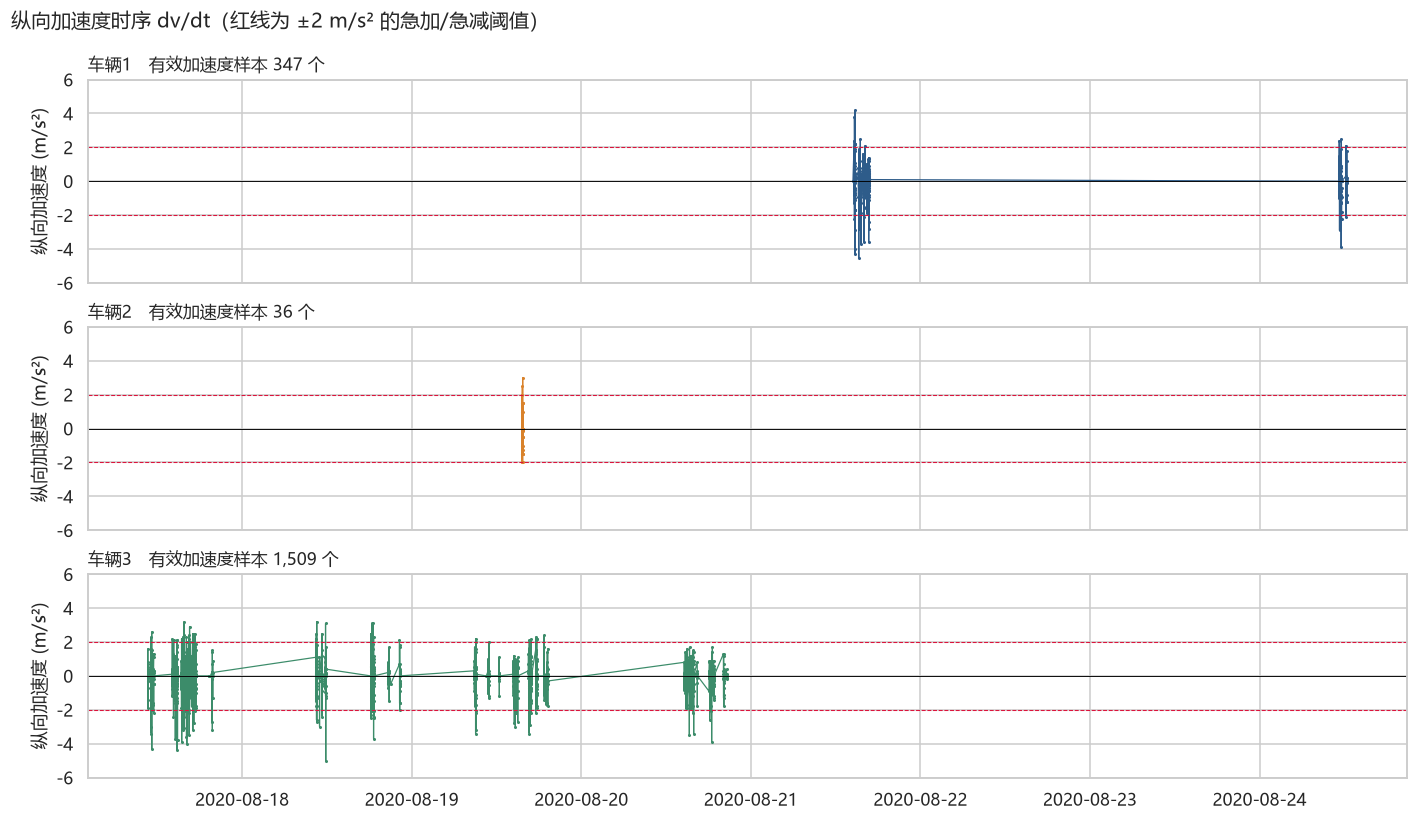

车辆1: n= 347  中位数=+0.00  平均|a|=0.69   p95|a|=2.34  最大加速=+4.20  最大减速=-4.50
车辆2: n=  36  中位数=+0.00  平均|a|=1.14   p95|a|=2.12  最大加速=+3.00  最大减速=-2.00
车辆3: n=1509  中位数=+0.00  平均|a|=0.67   p95|a|=2.20  最大加速=+3.20  最大减速=-5.00


In [6]:
# 纵向加速度：用相邻窗口的车速差反推 dv/dt，比原始三轴更贴近车辆运动学
def accel_series(device, max_dt=30.0, clip=5.0):
    v = (clean.loc[clean.deviceId.eq(device), ["timestamp", "Vehicle speed"]]
         .dropna(subset=["Vehicle speed"]).sort_values("timestamp"))
    dt = v.timestamp.diff().dt.total_seconds()
    dv = v["Vehicle speed"].diff()
    a = dv / dt
    a = a.where((dt > 0) & (dt <= max_dt))
    a = a.where(a.abs() <= clip)          # 剔除物理上不可能的跳变
    return pd.Series(a.to_numpy(), index=v.timestamp).dropna()


fig, axes = plt.subplots(3, 1, figsize=(13, 7.6), sharex=True)
for ax, dev in zip(axes, device_ids):
    a = accel_series(dev)
    ax.plot(a.index, a.values, lw=0.8, color=COLORS[dev], marker=".", ms=2)
    ax.axhline(0, color="black", lw=0.6)
    for r in (-2, 2):
        ax.axhline(r, color="crimson", ls="--", lw=0.7)
    ax.set_title(f"{DEV_LABEL[dev]}　有效加速度样本 {len(a):,} 个", loc="left", fontsize=11)
    ax.set_ylabel("纵向加速度 (m/s²)")
    ax.set_ylim(-6, 6)
fig.suptitle("纵向加速度时序 dv/dt（红线为 ±2 m/s² 的急加/急减阈值）", x=0.01, ha="left", fontsize=13)
fig.tight_layout()
save(fig, "B04_acceleration_timeseries.png")
plt.show()

for dev in device_ids:
    a = accel_series(dev)
    mean_abs = a.abs().mean()
    p95_abs = a.abs().quantile(.95)
    print(f"{DEV_LABEL[dev]}: n={len(a):>4}  中位数={a.median():+.2f}  "
          f"平均|a|={mean_abs:.2f}   p95|a|={p95_abs:.2f}  "
          f"最大加速={a.max():+.2f}  最大减速={a.min():+.2f}")

已保存 figures\B05_typical_day_zoom.png


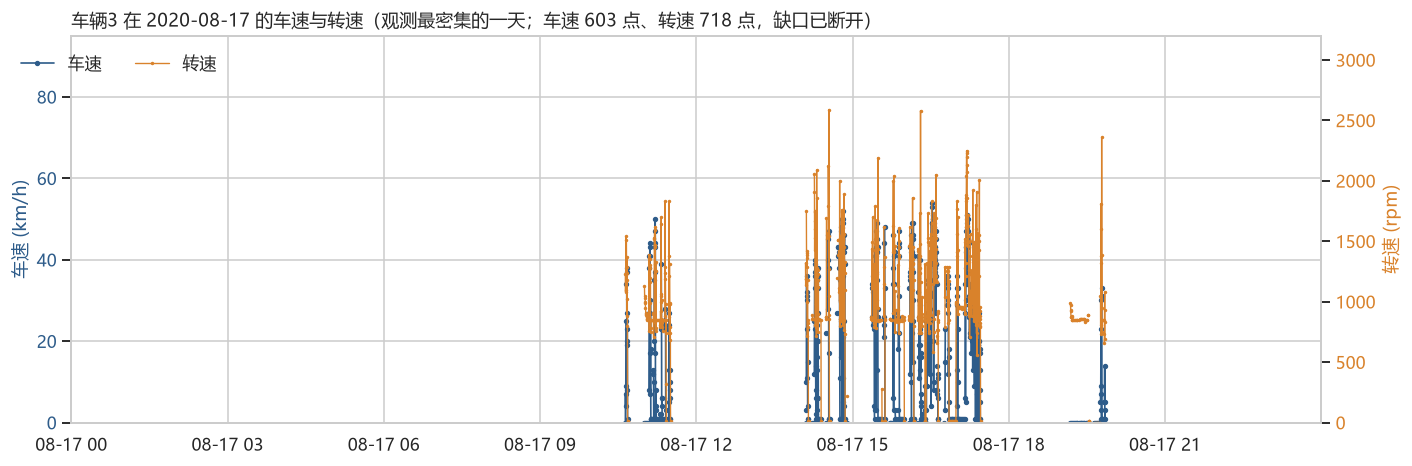

In [7]:
# 放大：选观测最密集的一天看细部形态
target = device_ids[2]
v3 = clean[clean.deviceId.eq(target)].dropna(subset=["Vehicle speed"])
day = v3.timestamp.dt.date.value_counts().idxmax()
mask = (clean.timestamp.dt.date == day) & clean.deviceId.eq(target)

sp = clean.loc[mask].dropna(subset=["Vehicle speed"])
rp = clean.loc[mask].dropna(subset=["ENGINE RPM"])

# 同样铺到 10 秒网格再画：长缺口必须真正断开，否则会连出跨小时的斜线，制造「连续变化」的错觉
grid = pd.date_range(pd.Timestamp(day), periods=8640, freq=STEP)
sp_s = sp.set_index("timestamp")["Vehicle speed"].sort_index().reindex(grid)
rp_s = rp.set_index("timestamp")["ENGINE RPM"].sort_index().reindex(grid)

fig, ax1 = plt.subplots(figsize=(13, 4.4))
ax1.plot(grid, sp_s.to_numpy(dtype=float), color="#2E5C8A", lw=1.1, marker="o", ms=2.5, label="车速")
ax1.set_ylabel("车速 (km/h)", color="#2E5C8A")
ax1.tick_params(axis="y", labelcolor="#2E5C8A")
ax1.set_ylim(0, 95)
ax1.set_xlim(grid[0], grid[-1])

ax2 = ax1.twinx()
ax2.plot(grid, rp_s.to_numpy(dtype=float), color="#D9822B", lw=0.9, marker=".", ms=2.5, label="转速")
ax2.set_ylabel("转速 (rpm)", color="#D9822B")
ax2.tick_params(axis="y", labelcolor="#D9822B")
ax2.set_ylim(0, 3200)
ax2.grid(False)

ax1.set_title(f"{DEV_LABEL[target]} 在 {day} 的车速与转速（观测最密集的一天；"
              f"车速 {len(sp)} 点、转速 {len(rp)} 点，缺口已断开）", loc="left")
fig.legend(loc="upper left", bbox_to_anchor=(0.01, 0.90), frameon=False, ncol=2)
fig.tight_layout()
save(fig, "B05_typical_day_zoom.png")
plt.show()

## 4. 三台车辆的运行特征对比

### 4.1 运行特征指标表

先给一张汇总表，把「车速水平、转速水平、静止比例、加减速强度」四类指标并排列出。

In [8]:
def device_stats(dev):
    d = clean.loc[clean.deviceId.eq(dev)]
    v = d.dropna(subset=["Vehicle speed"])
    r = d.dropna(subset=["ENGINE RPM"])
    a = accel_series(dev)
    both = d.dropna(subset=["Vehicle speed", "ENGINE RPM"])
    idle_flag = d["IDLING"]
    obs_flag = idle_flag.dropna()

    return {
        "窗口数": len(d),
        "车速观测数": len(v),
        "平均车速 (km/h)": v["Vehicle speed"].mean(),
        "车速中位数": v["Vehicle speed"].median(),
        "车速 p95": v["Vehicle speed"].quantile(.95),
        "最高车速": v["Vehicle speed"].max(),
        "平均转速 (rpm)": r["ENGINE RPM"].mean(),
        "转速 p95": r["ENGINE RPM"].quantile(.95),
        "高转速(>2500)占比": (r["ENGINE RPM"] > 2500).mean() * 100,
        "静止(v=0)占比": (v["Vehicle speed"] == 0).mean() * 100,
        "行驶(v>0)占比": (v["Vehicle speed"] > 0).mean() * 100,
        "怠速标志=1 占比": (obs_flag == 1).mean() * 100 if len(obs_flag) else np.nan,
        "平均 |a| (m/s²)": a.abs().mean(),
        "急加速(>2)占比": (a > 2).mean() * 100,
        "急减速(<-2)占比": (a < -2).mean() * 100,
        "转速-车速相关系数": both[["ENGINE RPM", "Vehicle speed"]].corr().iloc[0, 1] if len(both) > 30 else np.nan,
    }


kpi = pd.DataFrame({DEV_LABEL[d]: device_stats(d) for d in device_ids}).T
print("说明：占比的分母均为该设备【有观测】的窗口数，不是全部窗口。")
kpi.round(2)

说明：占比的分母均为该设备【有观测】的窗口数，不是全部窗口。


,窗口数,车速观测数,平均车速 (km/h),车速中位数,车速 p95,最高车速,平均转速 (rpm),转速 p95,高转速(>2500)占比,静止(v=0)占比,行驶(v>0)占比,怠速标志=1 占比,平均 |a| (m/s²),急加速(>2)占比,急减速(<-2)占比,转速-车速相关系数
车辆1,1547.0,396.0,40.21,49.0,74.25,92.0,1501.29,2514.0,5.28,3.54,96.46,48.43,0.69,3.17,4.61,0.82
车辆2,767.0,88.0,21.14,5.0,170.00,175.0,2322.22,9000.0,18.89,43.18,56.82,25.33,1.14,5.56,0.00,0.98
车辆3,32992.0,1767.0,21.68,22.0,49.00,79.0,1082.40,1894.5,0.44,7.64,92.36,49.71,0.67,2.72,3.58,0.70


### 4.2 工况结构：速度分箱与怠速/行驶比例

「工况」用两个互补的视角刻画：一是车速分箱构成，二是车辆状态（熄火停车 / 怠速 / 行驶）。

已保存 figures\B06_speed_bin_mix.png


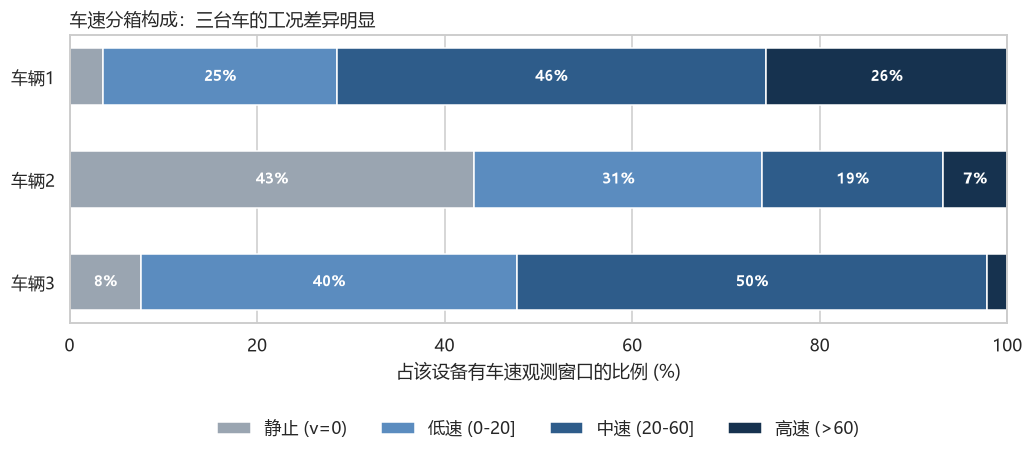

各速度区间窗口数：
speed_bin  静止 (v=0)  低速 (0-20]  中速 (20-60]  高速 (>60)
vehicle                                             
车辆1              14         99         181       102
车辆2              38         27          17         6
车辆3             135        708         886        38


In [9]:
SPEED_BINS = [-0.1, 0.1, 20, 60, 400]
SPEED_LABELS = ["静止 (v=0)", "低速 (0-20]", "中速 (20-60]", "高速 (>60)"]

speed_obs = clean.dropna(subset=["Vehicle speed"]).copy()
speed_obs["speed_bin"] = pd.cut(speed_obs["Vehicle speed"], bins=SPEED_BINS, labels=SPEED_LABELS)
share = (pd.crosstab(speed_obs.vehicle, speed_obs.speed_bin, normalize="index") * 100)
share = share.reindex(columns=SPEED_LABELS, fill_value=0)

fig, ax = plt.subplots(figsize=(11, 3.4))
left = np.zeros(len(share))
bin_colors = ["#9AA5B1", "#5B8CBF", "#2E5C8A", "#16324F"]
for lab, c in zip(SPEED_LABELS, bin_colors):
    vals = share[lab].values
    ax.barh(share.index, vals, left=left, color=c, label=lab, height=0.55)
    for i, (l, w) in enumerate(zip(left, vals)):
        if w > 4:
            ax.text(l + w / 2, i, f"{w:.0f}%", ha="center", va="center",
                    color="white", fontsize=10, fontweight="bold")
    left += vals
ax.set_xlim(0, 100)
ax.set_xlabel("占该设备有车速观测窗口的比例 (%)")
ax.set_title("车速分箱构成：三台车的工况差异明显", loc="left")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.28), frameon=False)
ax.invert_yaxis()
save(fig, "B06_speed_bin_mix.png")
plt.show()

print("各速度区间窗口数：")
print(pd.crosstab(speed_obs.vehicle, speed_obs.speed_bin).reindex(columns=SPEED_LABELS, fill_value=0).to_string())

已保存 figures\B07_idle_driving_share.png


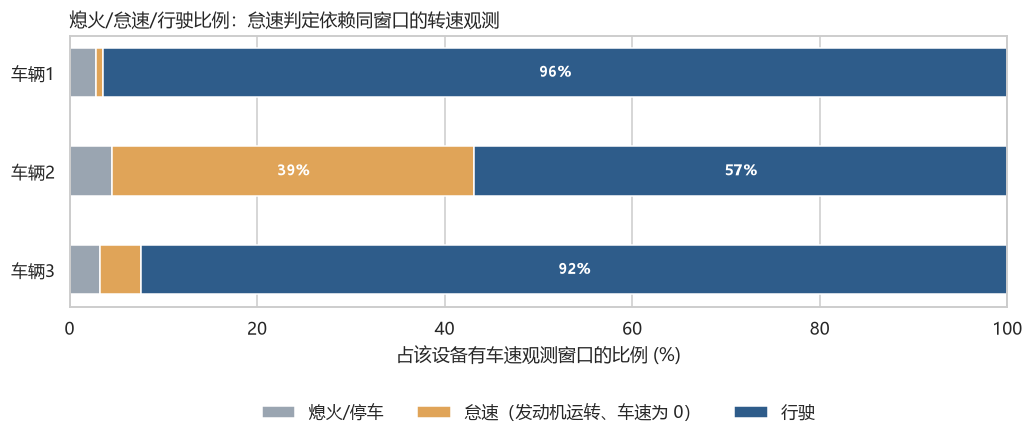

各类窗口数：
state    熄火/停车  怠速（发动机运转、车速为 0）    行驶
vehicle                              
车辆1         11                3   382
车辆2          4               34    50
车辆3         58               77  1632

注意：没有转速观测的 v=0 窗口只能归入「熄火/停车」，因此怠速比例是下界。

IDLING 标志共 1,107 个观测，其中 =1 的 530 个。
IDLING=1 且车速>0 的占 79.1%，中位车速 1 km/h，中位转速 860 rpm。
可见 IDLING=1 更接近「低负荷/低速滑行」，而不是严格的「车速为 0」。本报告因此以车速+转速度量怠速，IDLING 仅作交叉参考。


In [10]:
# 车辆状态三分：熄火停车 / 怠速 / 行驶
def state_of(row):
    v, rpm = row["Vehicle speed"], row["ENGINE RPM"]
    if pd.isna(v):
        return np.nan
    if v == 0:
        if pd.notna(rpm) and rpm >= 400:
            return "怠速（发动机运转、车速为 0）"
        return "熄火/停车"
    return "行驶"


so = clean.dropna(subset=["Vehicle speed"]).copy()
so["state"] = so.apply(state_of, axis=1)
state_labels = ["熄火/停车", "怠速（发动机运转、车速为 0）", "行驶"]
share2 = pd.crosstab(so.vehicle, so.state, normalize="index").reindex(columns=state_labels, fill_value=0) * 100

fig, ax = plt.subplots(figsize=(11, 3.2))
left = np.zeros(len(share2))
for lab, c in zip(state_labels, ["#9AA5B1", "#E0A458", "#2E5C8A"]):
    vals = share2[lab].values
    ax.barh(share2.index, vals, left=left, color=c, label=lab, height=0.5)
    for i, (l, w) in enumerate(zip(left, vals)):
        if w > 5:
            ax.text(l + w / 2, i, f"{w:.0f}%", ha="center", va="center",
                    color="white", fontsize=10, fontweight="bold")
    left += vals
ax.set_xlim(0, 100)
ax.invert_yaxis()
ax.set_xlabel("占该设备有车速观测窗口的比例 (%)")
ax.set_title("熄火/怠速/行驶比例：怠速判定依赖同窗口的转速观测", loc="left")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.3), frameon=False)
save(fig, "B07_idle_driving_share.png")
plt.show()

print("各类窗口数：")
print(pd.crosstab(so.vehicle, so.state).reindex(columns=state_labels, fill_value=0).to_string())
print("\n注意：没有转速观测的 v=0 窗口只能归入「熄火/停车」，因此怠速比例是下界。")

# IDLING 标志与「车速为 0」并不等价，必须单独说明，否则会得出矛盾的怠速比例
fl = clean.dropna(subset=["IDLING"])
sub = fl.dropna(subset=["Vehicle speed"])
idle1 = sub[sub.IDLING == 1]
print(f"\nIDLING 标志共 {len(fl):,} 个观测，其中 =1 的 {int((fl.IDLING == 1).sum()):,} 个。")
print(f"IDLING=1 且车速>0 的占 {(idle1['Vehicle speed'] > 0).mean():.1%}，"
      f"中位车速 {idle1['Vehicle speed'].median():.0f} km/h，"
      f"中位转速 {fl.loc[fl.IDLING == 1, 'ENGINE RPM'].median():.0f} rpm。")
print("可见 IDLING=1 更接近「低负荷/低速滑行」，而不是严格的「车速为 0」。"
      "本报告因此以车速+转速度量怠速，IDLING 仅作交叉参考。")

### 4.3 加减速习惯

加减速习惯用 **dv/dt 分布**刻画：看分布的宽度（驾驶是否平顺）和两侧尾部（是否频繁急加急减）。
这里不用原始三轴加速度——第 2 节已看到三轴幅值均在 9.4–9.9 m/s² 附近，包含重力分量且各设备安装朝向不同，
不能直接当作纵向加速度；第 6 节的相关性分析也显示 `ACCELERATION X` 与 dv/dt 几乎不相关（r≈-0.01）。

已保存 figures\B08_acceleration_habits.png


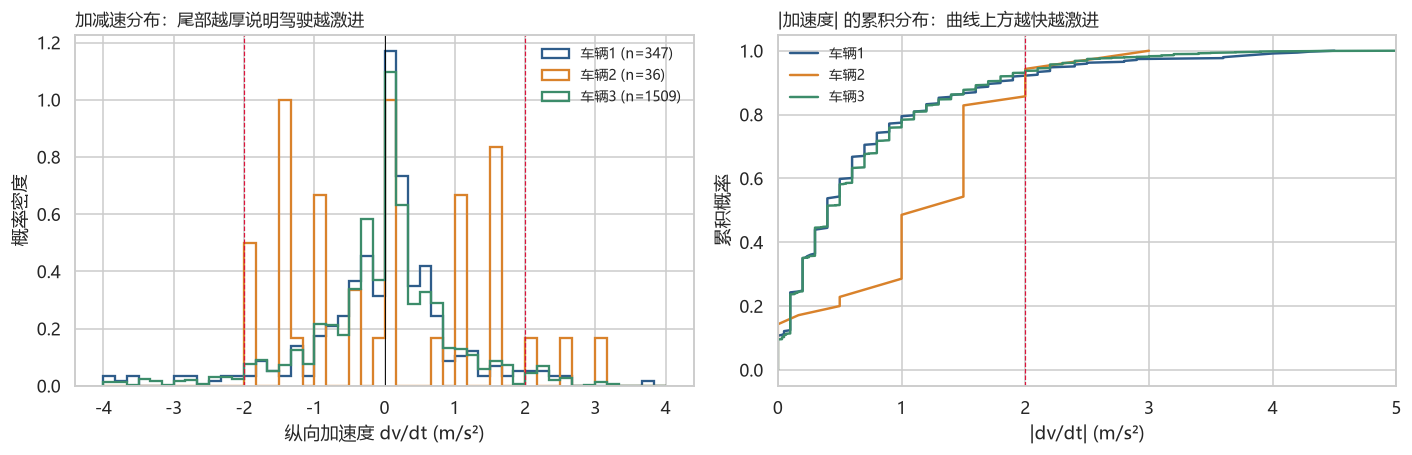

,样本数,加速占比 a>0.5,减速占比 a<-0.5,急加速 a>2,急减速 a<-2,|a| p95,加速/减速比
车辆,,,,,,,
车辆1,347,18.73,21.33,3.17,4.61,2.34,0.88
车辆2,36,36.11,38.89,5.56,0.00,2.12,0.93
车辆3,1509,20.01,21.80,2.72,3.58,2.20,0.92


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))

ax = axes[0]
bins = np.linspace(-4, 4, 49)
for dev in device_ids:
    a = accel_series(dev)
    ax.hist(a, bins=bins, density=True, histtype="step", lw=1.5,
            color=COLORS[dev], label=f"{DEV_LABEL[dev]} (n={len(a)})")
ax.axvline(0, color="black", lw=0.6)
for r in (-2, 2):
    ax.axvline(r, color="crimson", ls="--", lw=0.8)
ax.set_xlabel("纵向加速度 dv/dt (m/s²)")
ax.set_ylabel("概率密度")
ax.set_title("加减速分布：尾部越厚说明驾驶越激进", loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=9)

ax = axes[1]
for dev in device_ids:
    a = accel_series(dev).abs().sort_values()
    ax.plot(a.values, np.linspace(0, 1, len(a)), lw=1.6, color=COLORS[dev], label=DEV_LABEL[dev])
ax.axvline(2, color="crimson", ls="--", lw=0.8)
ax.set_xlabel("|dv/dt| (m/s²)")
ax.set_ylabel("累积概率")
ax.set_xlim(0, 5)
ax.set_title("|加速度| 的累积分布：曲线上方越快越激进", loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=9)

fig.tight_layout()
save(fig, "B08_acceleration_habits.png")
plt.show()

rows = []
for dev in device_ids:
    a = accel_series(dev)
    rows.append({
        "车辆": DEV_LABEL[dev], "样本数": len(a),
        "加速占比 a>0.5": (a > 0.5).mean() * 100,
        "减速占比 a<-0.5": (a < -0.5).mean() * 100,
        "急加速 a>2": (a > 2).mean() * 100,
        "急减速 a<-2": (a < -2).mean() * 100,
        "|a| p95": a.abs().quantile(.95),
        "加速/减速比": (a > 0.5).sum() / max((a < -0.5).sum(), 1),
    })
pd.DataFrame(rows).set_index("车辆").round(2)

### 4.4 转速—车速关系

转速与车速的比值间接反映传动比（挡位）。两者相关性高说明数据内部自洽，也可以作为「遥测可信度」的旁证。
需要注意：车辆2 的相关系数虽然接近 1，但它只有 88 个共同观测，且由 175 km/h / 9,000 rpm 的一对尖峰主导，
**不能**当作传动关系的证据，反而进一步说明该设备存在异常上报。

已保存 figures\B09_rpm_vs_speed.png


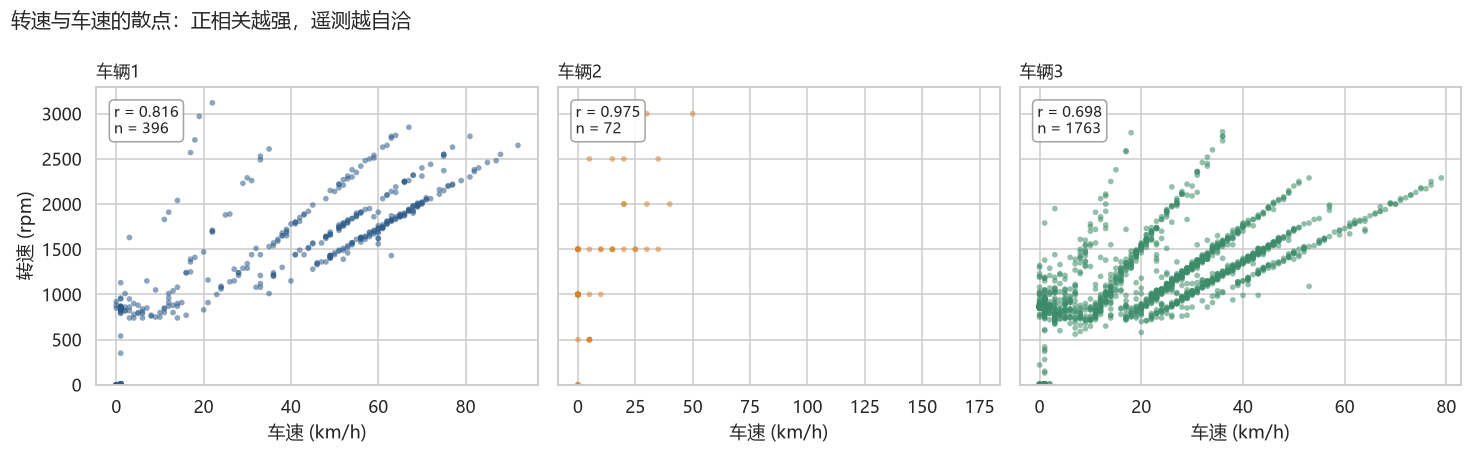

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.2), sharey=True)
for ax, dev in zip(axes, device_ids):
    d = clean.loc[clean.deviceId.eq(dev)].dropna(subset=["Vehicle speed", "ENGINE RPM"])
    ax.scatter(d["Vehicle speed"], d["ENGINE RPM"], s=14, alpha=0.55,
               color=COLORS[dev], edgecolors="none")
    if len(d) > 30:
        r = d[["Vehicle speed", "ENGINE RPM"]].corr().iloc[0, 1]
        ax.text(0.04, 0.94, f"r = {r:.3f}\nn = {len(d)}", transform=ax.transAxes,
                va="top", fontsize=10,
                bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="#999", alpha=0.9))
    ax.set_title(DEV_LABEL[dev], loc="left", fontsize=11)
    ax.set_xlabel("车速 (km/h)")
axes[0].set_ylabel("转速 (rpm)")
axes[0].set_ylim(0, 3300)
fig.suptitle("转速与车速的散点：正相关越强，遥测越自洽", x=0.01, ha="left", fontsize=13)
fig.tight_layout()
save(fig, "B09_rpm_vs_speed.png")
plt.show()

## 5. 车辆轨迹与位置可视化

### 5.1 先判定坐标口径

`position_1/2` 的量级（13.3 与 74.7）既可能是「纬度 13.3°N、经度 74.7°E」，也可能是反过来（纬度 74.7°N、经度 13.3°E）。
两种假设都能画出一条像样的线，所以不能靠看图判断。这里用**物理一致性**判别：
由相邻定位点的位移反推车速，与同窗口的 OBD 车速比较，谁更接近谁就是对的。
注意经度方向的实际距离要乘 `cos(纬度)`，两个假设的换算比例不同，因此可以区分。

In [13]:
pos_all = clean.dropna(subset=["position_1", "position_2"]).copy()
SENTINEL = (pos_all.position_1 == 0) & (pos_all.position_2 == 0)
print(f"定位记录 {len(pos_all):,} 条，其中 (0,0,0) 无效占位 {int(SENTINEL.sum()):,} 条 "
      f"({SENTINEL.mean():.1%})")

pos = pos_all[~SENTINEL].sort_values(["deviceId", "timestamp"]).copy()
pos["dt"] = pos.groupby("deviceId").timestamp.diff().dt.total_seconds()
pos["d_position_1"] = pos.groupby("deviceId").position_1.diff()
pos["d_position_2"] = pos.groupby("deviceId").position_2.diff()
pair = pos[(pos.dt > 0) & (pos.dt <= 30)].copy()
pair = pair.dropna(subset=["Vehicle speed"])


def implied_speed(lat_col, lon_col, lat0):
    dy = pair[f"d_{lat_col}"] * 110.574
    dx = pair[f"d_{lon_col}"] * 111.320 * np.cos(np.radians(lat0))
    return np.hypot(dx, dy) / pair.dt * 3600


moving = (pair.d_position_1.abs() > 0) | (pair.d_position_2.abs() > 0)
moving &= np.hypot(pair.d_position_1, pair.d_position_2) < 0.01   # 排除 GPS 跳变

print("\n两种坐标假设下的「反推车速」与 OBD 车速比较：")
print(f"{'假设':40s} {'n':>6s} {'反推中位数':>12s} {'OBD中位数':>10s} {'中位绝对误差':>12s}")
for lat_col, lon_col, lat0, name in [
    ("position_1", "position_2", 13.35, "H1: position_1=纬度, position_2=经度"),
    ("position_2", "position_1", 74.74, "H2: position_2=纬度, position_1=经度"),
]:
    s = implied_speed(lat_col, lon_col, lat0)
    m = moving & np.isfinite(s) & pair["Vehicle speed"].notna()
    print(f"{name:40s} {int(m.sum()):>6d} {np.median(s[m]):>10.1f} km/h "
          f"{np.median(pair['Vehicle speed'][m]):>6.1f} km/h "
          f"{np.median(np.abs(s[m] - pair['Vehicle speed'][m])):>9.1f} km/h")

print("\n结论：H1 的反推车速与 OBD 车速高度吻合，故 position_1=纬度、position_2=经度、position_3=海拔(米)。")

定位记录 35,250 条，其中 (0,0,0) 无效占位 6,517 条 (18.5%)

两种坐标假设下的「反推车速」与 OBD 车速比较：
假设                                            n        反推中位数     OBD中位数       中位绝对误差
H1: position_1=纬度, position_2=经度           1674       29.3 km/h   29.0 km/h       4.0 km/h
H2: position_2=纬度, position_1=经度           1674       17.7 km/h   29.0 km/h       9.6 km/h

结论：H1 的反推车速与 OBD 车速高度吻合，故 position_1=纬度、position_2=经度、position_3=海拔(米)。


各设备的东西/南北跨度比： {'车辆1': 0.2, '车辆2': 0.69, '车辆3': 0.74}


已保存 figures\B10_trajectory_overview.png


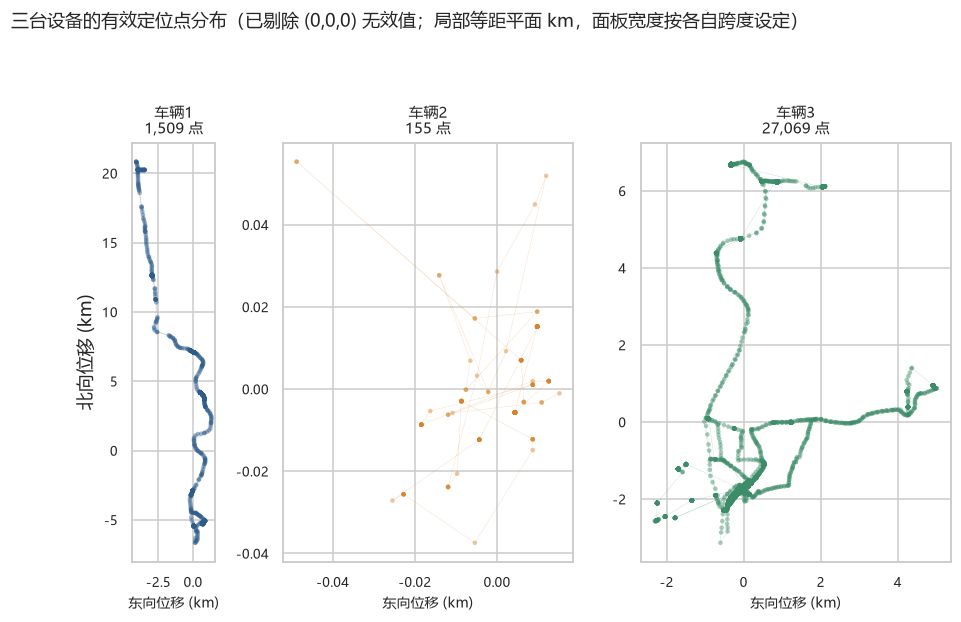

车辆1: 纬度 13.3173~13.5660, 经度 74.7000~74.7501, 东西跨度 5.43 km, 南北跨度 27.50 km, 唯一坐标 468 个, 海拔 -276~92 m
车辆2: 纬度 13.0496~13.0504, 经度 80.2430~80.2436, 东西跨度 0.06 km, 南北跨度 0.09 km, 唯一坐标 34 个, 海拔 -25~238 m
车辆3: 纬度 13.3173~13.4068, 经度 74.7235~74.7910, 东西跨度 7.32 km, 南北跨度 9.89 km, 唯一坐标 1,894 个, 海拔 -1677~503 m


In [14]:
def enu(d):
    '''经纬度 -> 以该设备质心为原点的局部等距平面坐标（km），便于等比例绘制。'''
    lat0 = d.position_1.mean()
    lon0 = d.position_2.mean()
    east = (d.position_2 - lon0) * 111.320 * np.cos(np.radians(lat0))
    north = (d.position_1 - lat0) * 110.574
    return east, north, lat0, lon0


PREP = {}
for dev in device_ids:
    _d = pos[pos.deviceId.eq(dev)]
    _e, _n, _lat0, _lon0 = enu(_d)
    PREP[dev] = {"d": _d, "e": _e, "n": _n, "lat0": _lat0, "lon0": _lon0}

# 面板宽度按各设备的东西/南北跨度比设定，配合 set_aspect("equal") 才不会出现大片留白
PANEL_RATIOS = []
for dev in device_ids:
    p = PREP[dev]
    ew = max(p["e"].max() - p["e"].min(), 0.05)
    ns = max(p["n"].max() - p["n"].min(), 0.05)
    PANEL_RATIOS.append(ew / ns)
print("各设备的东西/南北跨度比：",
      {DEV_LABEL[d]: float(f"{r:.2f}") for d, r in zip(device_ids, PANEL_RATIOS)})


fig, axes = plt.subplots(1, 3, figsize=(9.6, 6.4),
                         gridspec_kw={"width_ratios": PANEL_RATIOS, "wspace": 0.30})
for ax, dev in zip(axes, device_ids):
    p = PREP[dev]
    d, east, north = p["d"], p["e"], p["n"]
    ax.scatter(east, north, s=9, alpha=0.45, color=COLORS[dev], edgecolors="none")
    ax.plot(east, north, lw=0.3, color=COLORS[dev], alpha=0.25)
    ax.set_aspect("equal")                      # 保持真实方位比例
    # 车辆1 的航线是南北向细长条，面板本身很窄，标题只放设备名与点数，详细数值在下方表格
    ax.set_title(f"{DEV_LABEL[dev]}\n{len(d):,} 点", loc="center", fontsize=9.5)
    ax.set_xlabel("东向位移 (km)", fontsize=9)
    ax.tick_params(labelsize=8.5)
axes[0].set_ylabel("北向位移 (km)")

fig.suptitle("三台设备的有效定位点分布（已剔除 (0,0,0) 无效值；局部等距平面 km，面板宽度按各自跨度设定）",
             x=0.01, ha="left", fontsize=12)
fig.tight_layout()
save(fig, "B10_trajectory_overview.png")
plt.show()

for dev in device_ids:
    d = pos[pos.deviceId.eq(dev)]
    east, north, lat0, lon0 = enu(d)
    print(f"{DEV_LABEL[dev]}: 纬度 {d.position_1.min():.4f}~{d.position_1.max():.4f}, "
          f"经度 {d.position_2.min():.4f}~{d.position_2.max():.4f}, "
          f"东西跨度 {east.max()-east.min():.2f} km, 南北跨度 {north.max()-north.min():.2f} km, "
          f"唯一坐标 {d[['position_1', 'position_2']].drop_duplicates().shape[0]:,} 个, "
          f"海拔 {d.position_3.min():.0f}~{d.position_3.max():.0f} m")

已保存 figures\B11_trajectory_time_order.png


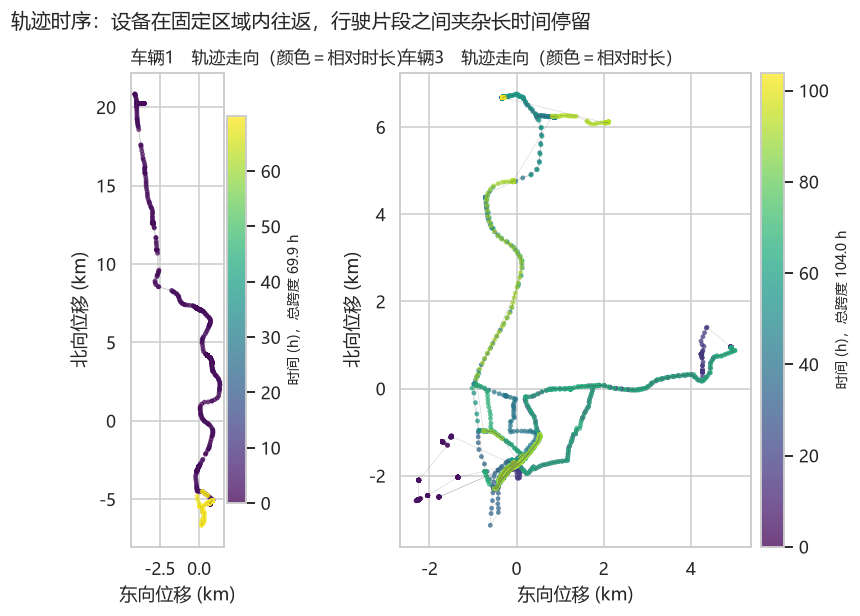

In [15]:
# 按时间着色，看轨迹的行走顺序
show = [device_ids[0], device_ids[2]]
sub_ratios = [PANEL_RATIOS[device_ids.index(d)] for d in show]

fig, axes = plt.subplots(1, 2, figsize=(2 * 3.2 * sum(sub_ratios) + 2.4, 5.6),
                         gridspec_kw={"width_ratios": sub_ratios, "wspace": 0.34})
for ax, dev in zip(axes, show):
    p = PREP[dev]
    d = p["d"]
    ts = d.timestamp.to_numpy()
    order = np.argsort(ts)
    east = p["e"].to_numpy()[order]
    north = p["n"].to_numpy()[order]
    tt = (ts[order] - ts.min()) / np.timedelta64(1, "h")
    sc = ax.scatter(east, north, c=tt, cmap="viridis", s=10, alpha=0.75, edgecolors="none")
    ax.plot(east, north, color="#444", lw=0.25, alpha=0.35)
    ax.set_title(f"{DEV_LABEL[dev]}　轨迹走向（颜色＝相对时长）", loc="left", fontsize=11)
    ax.set_xlabel("东向位移 (km)")
    ax.set_ylabel("北向位移 (km)")
    ax.set_aspect("equal")
    cb = fig.colorbar(sc, ax=ax, pad=0.02)
    cb.set_label(f"时间 (h)，总跨度 {tt.max():.1f} h", fontsize=9)
fig.suptitle("轨迹时序：设备在固定区域内往返，行驶片段之间夹杂长时间停留",
             x=0.01, ha="left", fontsize=13)
fig.tight_layout()
save(fig, "B11_trajectory_time_order.png")
plt.show()

### 5.2 海拔与定位质量

`position_3`（海拔）的取值极不稳定，需要单独看。定位有效性也可以用「GPS 反推车速 vs OBD 车速」的整体一致性来验证。

已保存 figures\B12_altitude_timeseries.png


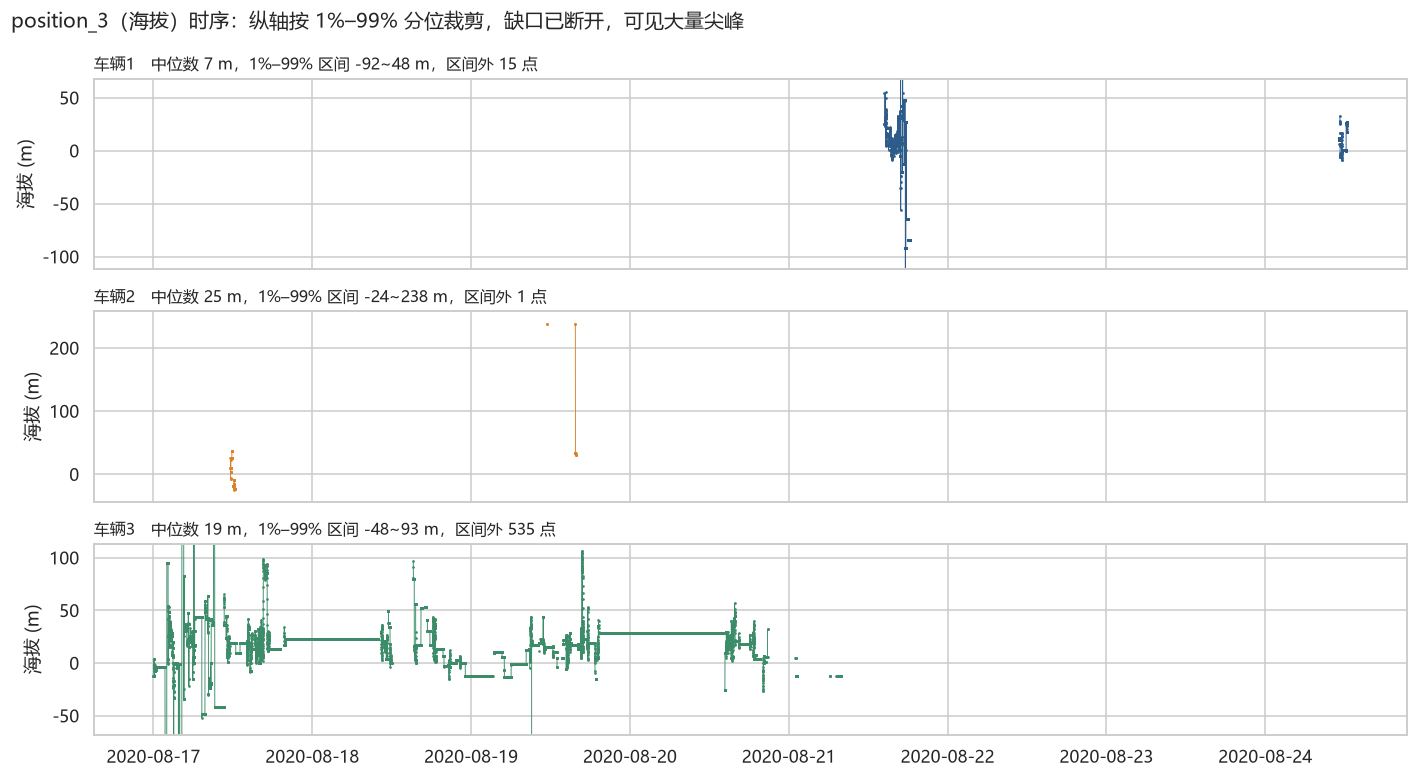

海拔异常统计（|海拔| > 200 m 记为不合理）：
  车辆1: 1 / 1,509 点 (0.1%)，极值 -276 ~ 92 m
  车辆2: 4 / 155 点 (2.6%)，极值 -25 ~ 238 m
  车辆3: 226 / 27,069 点 (0.8%)，极值 -1677 ~ 503 m


In [16]:
fig, axes = plt.subplots(3, 1, figsize=(13, 7.2), sharex=True)
for ax, dev in zip(axes, device_ids):
    d = pos[pos.deviceId.eq(dev)].sort_values("timestamp")
    s = gap_series(dev, "position_3", frame=pos)     # 同样在缺口处断线
    ax.plot(s.index, s.to_numpy(dtype=float), lw=0.6, color=COLORS[dev], marker=".", ms=1.5)
    lo, hi = d.position_3.quantile(.01), d.position_3.quantile(.99)
    ax.set_ylim(lo - 20, hi + 20)
    n_out = int(((d.position_3 < lo) | (d.position_3 > hi)).sum())
    ax.set_ylabel("海拔 (m)")
    ax.set_title(f"{DEV_LABEL[dev]}　中位数 {d.position_3.median():.0f} m，"
                 f"1%–99% 区间 {lo:.0f}~{hi:.0f} m，区间外 {n_out:,} 点", loc="left", fontsize=10.5)
fig.suptitle("position_3（海拔）时序：纵轴按 1%–99% 分位裁剪，缺口已断开，可见大量尖峰",
             x=0.01, ha="left", fontsize=13)
fig.tight_layout()
save(fig, "B12_altitude_timeseries.png")
plt.show()

print("海拔异常统计（|海拔| > 200 m 记为不合理）：")
for dev in device_ids:
    d = pos[pos.deviceId.eq(dev)]
    bad = d[d.position_3.abs() > 200]
    print(f"  {DEV_LABEL[dev]}: {len(bad):,} / {len(d):,} 点 ({len(bad)/len(d):.1%})，"
          f"极值 {d.position_3.min():.0f} ~ {d.position_3.max():.0f} m")

已保存 figures\B13_gps_vs_obd_speed.png


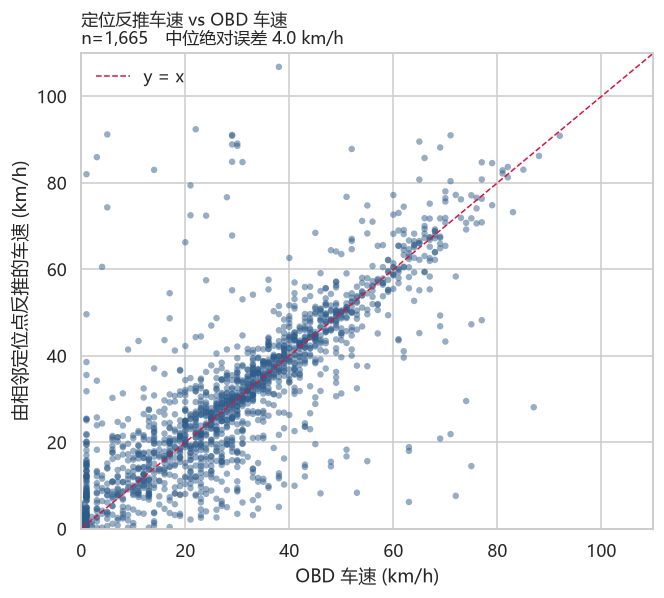

误差中位数 +0.5 km/h，|误差|≤10 km/h 的比例 77.7%。
定位点间隔较大时（10 秒内只取到一个定位点），两者必然存在偏差，故不追求高相关，只做量级校验。


In [17]:
# GPS 反推速度 vs OBD 车速：定位数据可信度的整体检验
s_h1 = implied_speed("position_1", "position_2", 13.35)
m = moving & np.isfinite(s_h1) & pair["Vehicle speed"].notna() & (s_h1 < 200)

fig, ax = plt.subplots(figsize=(6.2, 5.6))
ax.scatter(pair["Vehicle speed"][m], s_h1[m], s=18, alpha=0.5,
           color="#2E5C8A", edgecolors="none")
lim = (0, 110)
ax.plot(lim, lim, color="crimson", ls="--", lw=1, label="y = x")
ax.set_xlim(*lim)
ax.set_ylim(*lim)
r = np.corrcoef(pair["Vehicle speed"][m], s_h1[m])[0, 1]
ax.set_xlabel("OBD 车速 (km/h)")
ax.set_ylabel("由相邻定位点反推的车速 (km/h)")
ax.set_title(f"定位反推车速 vs OBD 车速\nn={int(m.sum()):,}　中位绝对误差 "
             f"{np.median(np.abs(s_h1[m] - pair['Vehicle speed'][m])):.1f} km/h", loc="left", fontsize=11)
ax.legend(frameon=False)
fig.tight_layout()
save(fig, "B13_gps_vs_obd_speed.png")
plt.show()

err = (s_h1[m] - pair["Vehicle speed"][m])
print(f"误差中位数 {err.median():+.1f} km/h，"
      f"|误差|≤10 km/h 的比例 {(err.abs() <= 10).mean():.1%}。"
      "\n定位点间隔较大时（10 秒内只取到一个定位点），两者必然存在偏差，故不追求高相关，只做量级校验。")

## 6. 变量相关性分析

### 6.1 相关矩阵的稀疏陷阱

直接对 53 个测量字段调用 `corr()` 会得到一个几乎填满的矩阵，但很多格子背后的**共同观测只有个位数**，
这种相关系数没有意义。所以这里同时计算「共同非空样本数矩阵」，**样本数少于 50 的格子直接置空**，不参与解读。

以下字段与其它字段的共同观测均不足 50 个，无法解读，已从热力图剔除：


  进气流量


已保存 figures\B14_corr_core.png


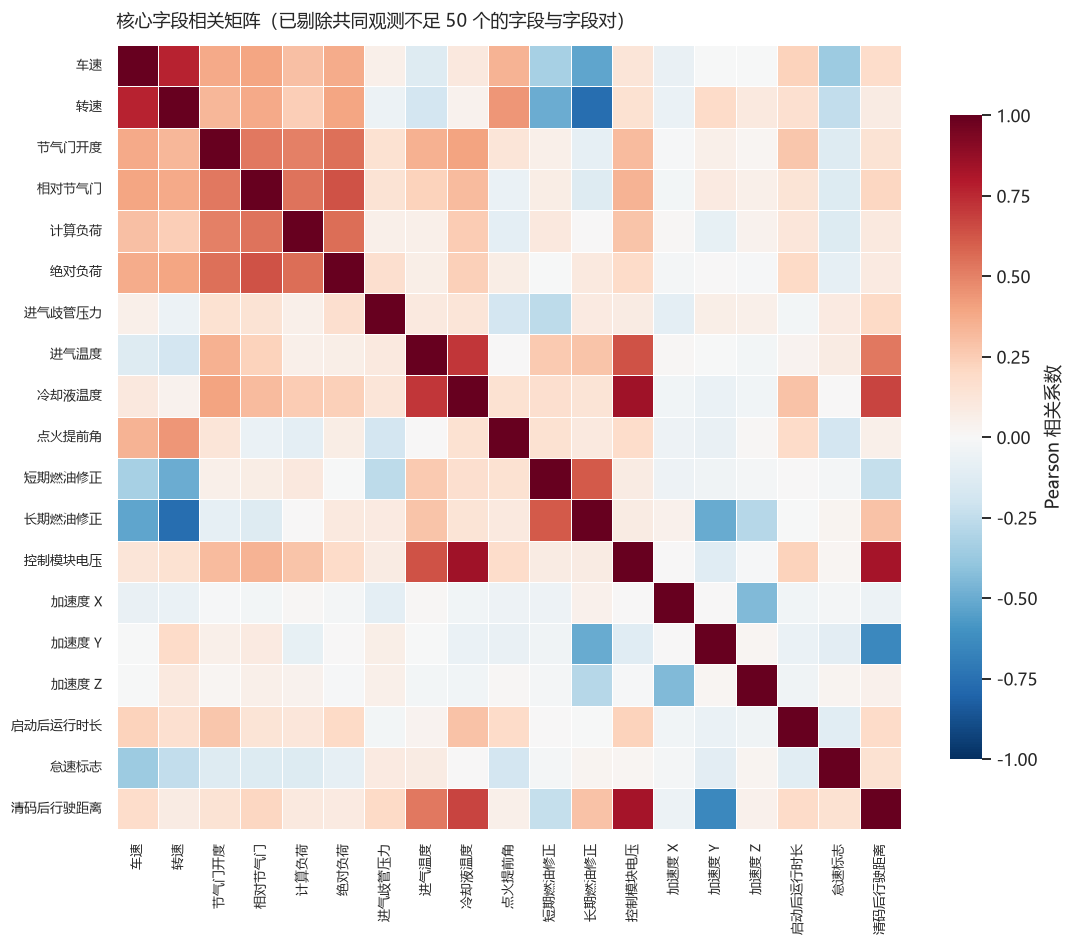

矩阵共 361 个格子，可解读 361 个，因样本不足置空 0 个。


In [18]:
CORE_VARS = [
    "Vehicle speed", "ENGINE RPM", "THROTTLE POSITION", "RELATIVE THROTTLE POSITION",
    "CALCULATED ENGINE LOAD", "ABSOLUTE LOAD VALUE", "MAF AIR FLOW RATE",
    "INTAKE MANIFOLD ABSOLUTE PRESSURE", "AIR INTAKE TEMPERATURE",
    "ENGINE COOLANT TEMPERATURE", "TIMING ADVANCE", "SHORT TERM FUEL TRIM BANK 1",
    "LONG TERM FUEL TRIM BANK 1", "CONTROL MODULE VOLTAGE",
    "ACCELERATION X", "ACCELERATION Y", "ACCELERATION Z",
    "RUN TIME SINCE ENGINE START", "IDLING", "DISTANCE TRAVELED SINCE CODES CLEARED",
]

CORE_CN = {
    "Vehicle speed": "车速",
    "ENGINE RPM": "转速",
    "THROTTLE POSITION": "节气门开度",
    "RELATIVE THROTTLE POSITION": "相对节气门",
    "CALCULATED ENGINE LOAD": "计算负荷",
    "ABSOLUTE LOAD VALUE": "绝对负荷",
    "MAF AIR FLOW RATE": "进气流量",
    "INTAKE MANIFOLD ABSOLUTE PRESSURE": "进气歧管压力",
    "AIR INTAKE TEMPERATURE": "进气温度",
    "ENGINE COOLANT TEMPERATURE": "冷却液温度",
    "TIMING ADVANCE": "点火提前角",
    "SHORT TERM FUEL TRIM BANK 1": "短期燃油修正",
    "LONG TERM FUEL TRIM BANK 1": "长期燃油修正",
    "CONTROL MODULE VOLTAGE": "控制模块电压",
    "ACCELERATION X": "加速度 X",
    "ACCELERATION Y": "加速度 Y",
    "ACCELERATION Z": "加速度 Z",
    "RUN TIME SINCE ENGINE START": "启动后运行时长",
    "IDLING": "怠速标志",
    "DISTANCE TRAVELED SINCE CODES CLEARED": "清码后行驶距离",
}


def masked_corr(frame, min_n=50, method="pearson"):
    '''返回 (相关系数矩阵, 共同样本数矩阵)，并把 n<min_n 的格子置为 NaN。'''
    corr = frame.corr(method=method)
    X = frame.notna().to_numpy().astype(np.int64)
    nmat = pd.DataFrame(X.T @ X, index=frame.columns, columns=frame.columns)
    return corr.where(nmat >= min_n), nmat


corr_core, n_core = masked_corr(clean[CORE_VARS])

# 与其余所有字段的共同观测都不足 50 的变量，整行整列都是空白，留在图上只会造成「画错了」的误解
interp = corr_core.notna().sum() - 1
keep_core = interp[interp >= 3].index.tolist()
dropped = [c for c in CORE_VARS if c not in keep_core]
if dropped:
    print("以下字段与其它字段的共同观测均不足 50 个，无法解读，已从热力图剔除：")
    print("  " + "、".join(CORE_CN[c] for c in dropped))
corr_core = corr_core.loc[keep_core, keep_core]
n_core = n_core.loc[keep_core, keep_core]

fig, ax = plt.subplots(figsize=(11.5, 9.5))
labels = [CORE_CN[c] for c in keep_core]
sns.heatmap(corr_core, mask=corr_core.isna(), cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.4, linecolor="white",
            xticklabels=labels, yticklabels=labels, ax=ax,
            cbar_kws={"label": "Pearson 相关系数", "shrink": 0.8})
ax.set_title("核心字段相关矩阵（已剔除共同观测不足 50 个的字段与字段对）", loc="left", pad=12)
ax.tick_params(labelsize=8.5)
save(fig, "B14_corr_core.png")
plt.show()

print(f"矩阵共 {corr_core.size:,} 个格子，可解读 {int(corr_core.notna().sum().sum()):,} 个，"
      f"因样本不足置空 {int(corr_core.isna().sum().sum()):,} 个。")

53 个测量字段中，观测窗口数 ≥ 300 的有 43 个；其余字段进入相关性分析没有统计意义。
其中再剔除 6 个字段（与其它字段的共同观测均少于 30 个）。


已保存 figures\B15_corr_full.png


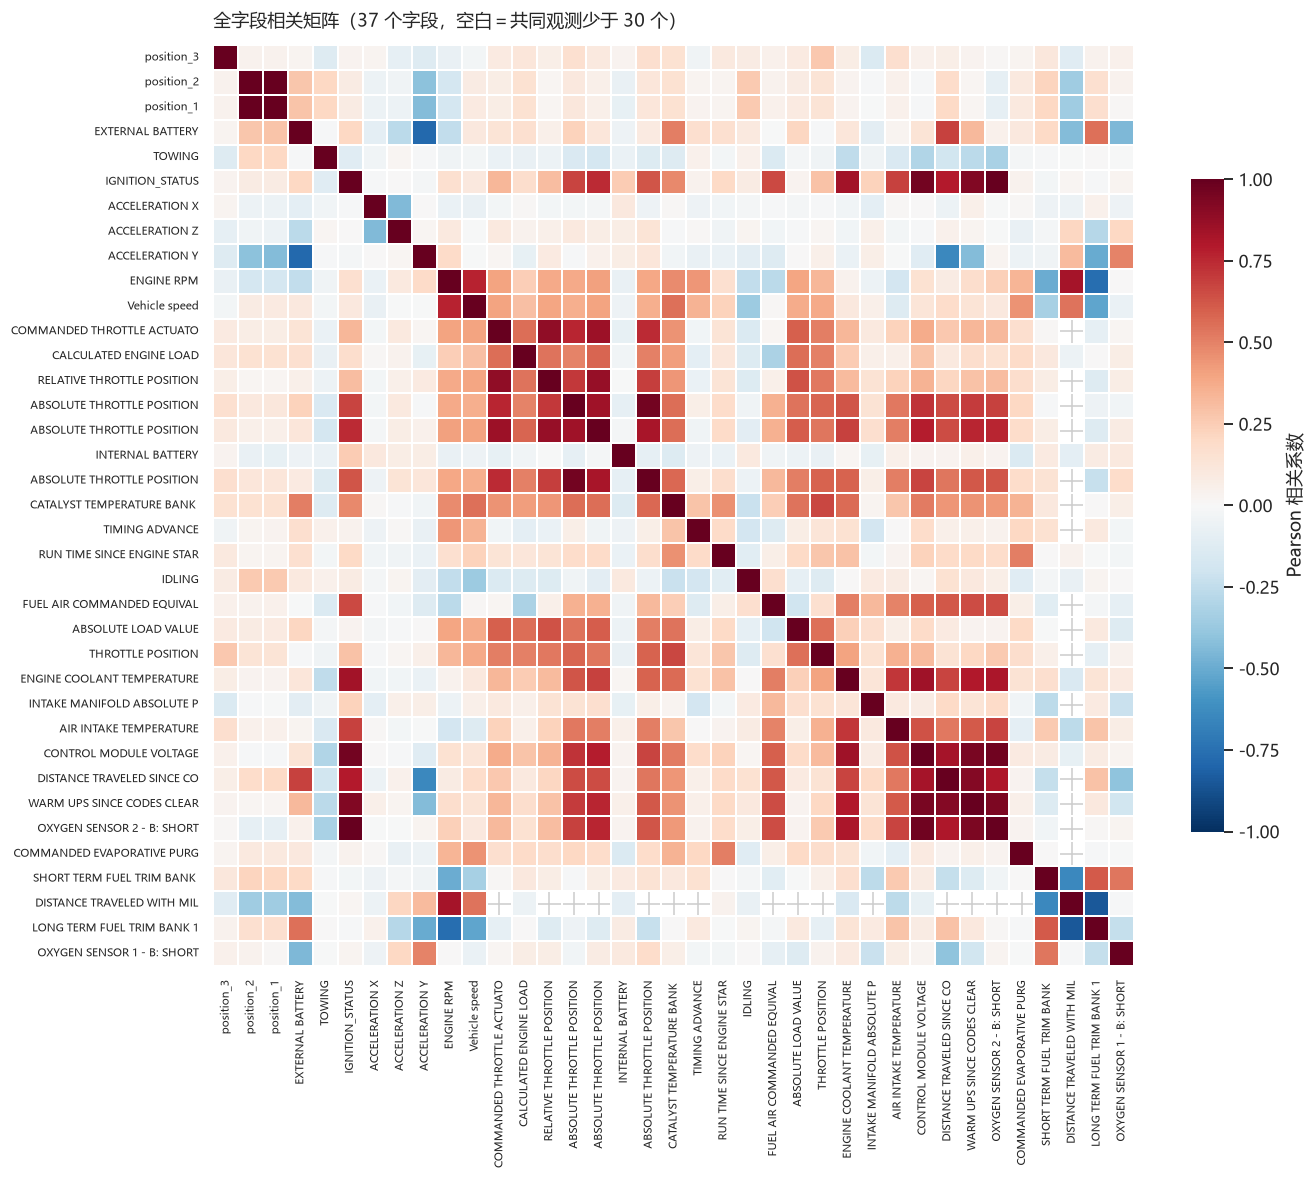

In [19]:
# 覆盖率足够、可以进入全字段矩阵的测量字段
coverage = clean[MEASUREMENTS].notna().sum()
keep = coverage[coverage >= 300].sort_values(ascending=False)
print(f"53 个测量字段中，观测窗口数 ≥ 300 的有 {len(keep)} 个；其余字段进入相关性分析没有统计意义。")

corr_full, n_full = masked_corr(clean[keep.index], min_n=30)

# 同样剔除整行整列都空白的字段（多为状态类编码，彼此几乎不在同一窗口共同出现）
interp_full = corr_full.notna().sum() - 1
keep_full = interp_full[interp_full >= 3].index.tolist()
print(f"其中再剔除 {len(keep) - len(keep_full)} 个字段（与其它字段的共同观测均少于 30 个）。")
corr_full = corr_full.loc[keep_full, keep_full]

fig, ax = plt.subplots(figsize=(13.5, 11))
sns.heatmap(corr_full, mask=corr_full.isna(), cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.3, linecolor="white", ax=ax,
            cbar_kws={"label": "Pearson 相关系数", "shrink": 0.7})
ax.set_xticklabels([c[:26] for c in keep_full], rotation=90, fontsize=7)
ax.set_yticklabels([c[:26] for c in keep_full], rotation=0, fontsize=7)
ax.set_title(f"全字段相关矩阵（{len(keep_full)} 个字段，空白＝共同观测少于 30 个）",
             loc="left", pad=12)
save(fig, "B15_corr_full.png")
plt.show()

### 6.2 与运行特征最相关的几组关系

从上面的矩阵里挑出可解读且相关系数较高的字段对，作为结论支撑。

In [20]:
pairs = []
cols = list(corr_core.columns)
for i, a in enumerate(cols):
    for b in cols[i + 1:]:
        r = corr_core.loc[a, b]
        if pd.notna(r):
            pairs.append({"字段A": CORE_CN[a], "字段B": CORE_CN[b],
                          "相关系数": r, "共同观测数": int(n_core.loc[a, b])})

pairs = pd.DataFrame(pairs)
pairs["|r|"] = pairs["相关系数"].abs()
top = pairs.sort_values("|r|", ascending=False).head(15).drop(columns="|r|")
top["相关系数"] = top["相关系数"].round(3)
top.reset_index(drop=True)

,字段A,字段B,相关系数,共同观测数
0,冷却液温度,控制模块电压,0.851,750
1,控制模块电压,清码后行驶距离,0.833,814
2,车速,转速,0.766,2231
3,转速,长期燃油修正,-0.759,667
4,进气温度,冷却液温度,0.712,764
5,冷却液温度,清码后行驶距离,0.674,742
6,加速度 Y,清码后行驶距离,-0.648,739
7,相对节气门,绝对负荷,0.638,986
8,进气温度,控制模块电压,0.635,818
9,短期燃油修正,长期燃油修正,0.612,666


## 7. 结论与局限

### 7.1 主要结论

**（1）时序特征：碎片化上报，不是连续行车记录。**
全周 35,306 个窗口里车速只有 2,251 个有效观测（6.4%），其中 1,701 个相邻观测恰好相隔 10 秒，
说明「短时行驶、长时间无上报」是常态。车辆1 车速水平最高（均值 40.2、中位 49、p95 74.3 km/h）；
车辆3 观测最完整（1,767 个车速窗口，中位 22 km/h）；
车辆2 只有 88 个车速观测，中位数 5 km/h，却出现 175 km/h 的孤立尖峰，判定为异常上报而非真实行驶。

**（2）工况结构：三台车分工况差异明显。**
车辆1 以中高速为主（中速 45.7% + 高速 25.8%，静止仅 3.5%）；
车辆3 以低速和中速为主（低速 40.1% + 中速 50.1%，高速仅 2.2%）；
车辆2 静止占 43.2%、低速 30.7%，其 6 个「高速」窗口全部来自 170–175 km/h 的尖峰。
按「车速=0 且转速≥400 rpm」判定怠速，车辆2 的怠速比例最高（38.6%），车辆3 为 4.4%，车辆1 仅 0.8%。
另外要提醒：`IDLING` 标志取值为 1 的窗口中约八成车速大于 0（中位车速 1 km/h、中位转速 860 rpm），
它更接近「低负荷滑行」而不是严格的怠速，直接拿它当怠速比例会得出与前文矛盾的结论。

**（3）加减速习惯：整体平顺，差异主要体现在尾部。**
平均 |dv/dt| 为 0.69（车辆1）／1.14（车辆2）／0.67（车辆3）m/s²，p95 均在 2.1–2.3 m/s²；
急加速（>2 m/s²）占比 3.2%／5.6%／2.7%，急减速（<-2 m/s²）占比 4.6%／0%／3.6%。
车辆2 的数值偏高，但其可用样本只有 36 个，不足以支撑「驾驶更激进」的结论。
同时必须强调：原始三轴 `ACCELERATION X/Y/Z` 的合幅值稳定在 9.4–9.9 m/s²（含重力分量），
且与 dv/dt 几乎不相关（r≈-0.01），**不能**把三轴读数直接当作车辆纵向加速度。

**（4）位置与轨迹：需先剔除无效定位，坐标顺序可以统计判定。**
剔除 18.5% 的 `(0,0,0)` 无效占位后：车辆1（1,509 点）与车辆3（27,069 点）位于 13.3°N／74.7°E 同一片区域，
车辆3 有 1,894 个唯一坐标、轨迹最密集；车辆1 有 468 个；车辆2 仅 34 个唯一坐标且位于 13.05°N／80.24°E，
与另两台相距约 600 km，且其 79% 的定位记录为无效占位。
用「相邻定位点反推车速」与 OBD 车速比对判定 `position_1`=纬度、`position_2`=经度：
该假设的中位绝对误差为 4.0 km/h，反向假设为 9.6 km/h，判别明确。
`position_3`（海拔）噪声极大，车辆3 出现 -1,677 m 这类不合理值（|海拔|>200 m 的点占 0.8%），不宜直接用于海拔分析。

**（5）相关性：物理关系可信，其余强相关要警惕取样偏差。**
车速与转速的相关系数为 0.766（共同观测 2,231 个，全表样本量最大的一对），符合传动关系，也印证遥测内部自洽。
冷却液温度与控制模块电压（0.851）、转速与长期燃油修正（-0.759）等强相关更可能来自
「共同观测集中在同一时段」的取样偏差，不应当作因果结论。

### 7.2 局限

1. **样本稀疏**：全表车速仅 2,251 个观测，车辆2 只有 88 个，任何结论都不具备统计代表性；
   每张图都标注了有效样本数，报告中的比例均以「有观测的窗口」为分母。
2. **时间不连续**：10 秒窗口只保留末次观测，真实采样可能更密，dv/dt 会被低估（窗口内部的加减速被平滑掉）。
3. **字段语义未确认**：POSITION 顺序、变量单位、状态编码仍待数据提供方确认；
   本报告的坐标判定是统计推断，不是官方口径；`IDLING` 编码同样待确认。
4. **未做告警交叉**：告警列（`code_*_count`、`single_alarmClass`）属于 C 部分，
   本报告未将其纳入运行特征，避免与 C 的建模特征产生泄漏或重复。

In [21]:
# 汇总输出：本次生成的全部图表
print("本次生成图表：")
for p in sorted(FIG.glob("B*.png")):
    print(f"  {p.name:<38} {p.stat().st_size/1024:6.1f} KB")

本次生成图表：
  B01_observation_coverage.png             83.7 KB
  B02_speed_timeseries.png                129.1 KB
  B03_rpm_timeseries.png                  165.8 KB
  B04_acceleration_timeseries.png         154.1 KB
  B05_typical_day_zoom.png                130.2 KB
  B06_speed_bin_mix.png                    62.3 KB
  B07_idle_driving_share.png               57.9 KB
  B08_acceleration_habits.png             106.2 KB
  B09_rpm_vs_speed.png                    189.9 KB
  B10_trajectory_overview.png             163.9 KB
  B11_trajectory_time_order.png           175.3 KB
  B12_altitude_timeseries.png             133.3 KB
  B13_gps_vs_obd_speed.png                199.2 KB
  B14_corr_core.png                       136.8 KB
  B15_corr_full.png                       283.5 KB
